# CheMeleon embeddings

- This notebook generates embeddings across several datasets using the **CheMeleon** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
from tqdm.auto import tqdm
import torch
from chemprop import featurizers, nn
from chemprop.data import BatchMolGraph
from chemprop.models import MPNN
from chemprop.nn import RegressionFFN
import rdkit
from rdkit import Chem
from rdkit.Chem import Mol, MolFromSmiles
import pandas as pd

from mordred import Calculator, descriptors
from mordred.error import Missing, Error

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

import plotly.express as px
import plotly.graph_objects as go

import sklearn 
from sklearn.metrics.pairwise import cosine_similarity


## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''

# Model set-up

In [3]:
class CheMeleonFingerprint:
    def __init__(self, device: str | torch.device | None = None):
        self.featurizer = featurizers.SimpleMoleculeMolGraphFeaturizer()

        ckpt_dir = Path.home() / ".chemprop"
        ckpt_dir.mkdir(exist_ok=True)
        mp_path = ckpt_dir / "chemeleon_mp.pt"

        if not mp_path.exists():
            urlretrieve(
                "https://zenodo.org/records/15460715/files/chemeleon_mp.pt",
                mp_path,
            )

        chemeleon_mp = torch.load(mp_path, weights_only=True, map_location="cpu")

        mp = nn.BondMessagePassing(**chemeleon_mp["hyper_parameters"])
        mp.load_state_dict(chemeleon_mp["state_dict"])

        self.model = MPNN(
            message_passing=mp,
            agg=nn.MeanAggregation(),
            predictor=RegressionFFN(input_dim=mp.output_dim),  # unused for fingerprints
        )

        if device is None:
            device = "cuda" if torch.cuda.is_available() else "cpu"

        self.model.to(device)
        self.model.eval()

    def _mol_from_input(self, x: str | Mol) -> Mol | None:
        if isinstance(x, str):
            return MolFromSmiles(x)
        return x

    def __call__(
        self,
        molecules: list[str | Mol],
        batch_size: int = 256,
        return_invalid_mask: bool = False,
    ):
        all_embeddings = []
        valid_mask = []

        for start in range(0, len(molecules), batch_size):
            batch = molecules[start : start + batch_size]

            mols = [self._mol_from_input(x) for x in batch]
            valid = [mol is not None for mol in mols]
            valid_mask.extend(valid)

            valid_mols = [mol for mol in mols if mol is not None]

            if not valid_mols:
                continue

            bmg = BatchMolGraph([self.featurizer(mol) for mol in valid_mols])
            bmg.to(device=self.model.device)

            with torch.inference_mode():
                emb = self.model.fingerprint(bmg)

            all_embeddings.append(emb.detach().cpu().numpy())

        embeddings = np.vstack(all_embeddings).astype(np.float32)

        if return_invalid_mask:
            return embeddings, np.array(valid_mask, dtype=bool)

        return embeddings

In [4]:
chemeleon_fingerprint = CheMeleonFingerprint()

/home/blake/miniconda3/envs/chemeleon-emb/lib/python3.11/site-packages/torch/cuda/__init__.py:1074: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


In [5]:
model = chemeleon_fingerprint.model

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params / 1e6:.3f}M")

Total parameters:     9,329,241
Trainable parameters: 9,329,241
Total parameters:     9.329M


# Generate MCES embeddings

In [ ]:
# Load distances
distances = np.load(MCES_PATH)

In [ ]:
# Check shapes
mces   = distances['mces']
smiles = distances['smiles']

# MCES is saved as a strict upper triangle of pairwise distances in row-major order
print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [ ]:
# Generate embeddings
embeddings, invalid_mask = chemeleon_fingerprint(
    smiles,
    batch_size=256,
    return_invalid_mask=True
)

# All molecules valid
print(np.sum(invalid_mask))

[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not removing hydrogen atom without neighbors
[17:41:01] WARNING: not r

In [ ]:
# Save cosine similarities in a flattened row-major, upper triangle format.

X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/CheMeleon MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

/home/blake/miniconda3/envs/chemeleon-emb/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 64/64 [08:42<00:00,  8.16s/it]


Expected length: 2012094766
Written length: 2012094766


In [ ]:
# Save indices in a flattened row-major, upper triangle format.

n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/CheMeleon MCES pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

/home/blake/miniconda3/envs/chemeleon-emb/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 63436/63436 [00:34<00:00, 1820.87it/s] 


Expected: 2012094766
Written: 2012094766


## Biogen

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()
print(len(smiles))

In [ ]:
embeddings, invalid_mask = chemeleon_fingerprint(
    smiles,
    batch_size=256,
    return_invalid_mask=True

)

# All smiles valid
print(np.sum(invalid_mask))

np.save('Biogen/CheMeleon Biogen embeddings.npy', embeddings)

## ZINC

In [ ]:
# ZINC file contains randomly sampled molecules. 
data   = pd.read_csv(ZINC30K_PATH)[:30000]
smiles = data['SMILES'].tolist()

In [ ]:
embeddings, invalid_mask = chemeleon_fingerprint(
    smiles,
    batch_size=256,
    return_invalid_mask=True
)

# All smiles valid
print(np.sum(invalid_mask))

np.save('ZINC/CheMeleon ZINC30K embeddings.npy', embeddings)

# MCES figure example

Cosine similarity: [[0.9936125]]


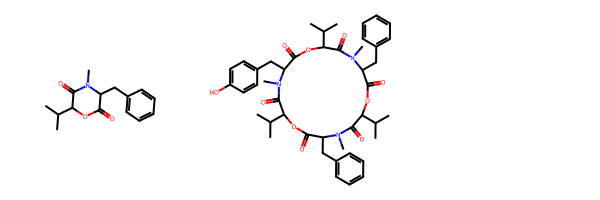

In [19]:
close_pair_a = "CC(C)C1C(=O)N(C(C(=O)O1)CC2=CC=CC=C2)C"
close_pair_b = "CC(C)C1C(=O)N(C(C(=O)OC(C(=O)N(C(C(=O)OC(C(=O)N(C(C(=O)O1)CC2=CC=CC=C2)C)C(C)C)CC3=CC=C(C=C3)O)C)C(C)C)CC4=CC=CC=C4)C"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings = chemeleon_fingerprint([close_pair_a, close_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

Cosine similarity: [[0.49400783]]


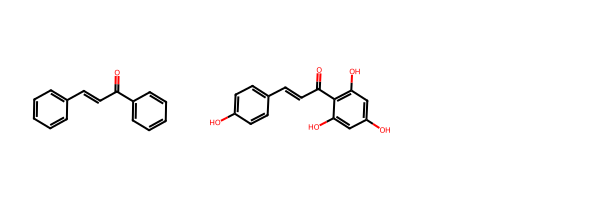

In [18]:
distant_pair_a = "C1=CC=C(C=C1)C=CC(=O)C2=CC=CC=C2"
distant_pair_b = "C1=CC(=CC=C1C=CC(=O)C2=C(C=C(C=C2O)O)O)O"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings = chemeleon_fingerprint([distant_pair_a, distant_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])